# 08 - Step 16 (Novelty 2): Vision-Language Models (`OpenAI CLIP ViT-B/16`) on LIGO Glitches
**L4 Group 23: Ismail Nooruddin, Munir Tariq, Ramsha Arshad**  
*CS/CE 351/363 - Artificial Intelligence, Fall 2026, Habib University*  
*Project Title: Classifying LIGO Glitches: Comparing CNNs and Simple Features*

---

### How to Run on Google Colab (3 Clicks — ~6–10 Minutes Total!)
1. Go to **`Runtime → Change runtime type`** and select **`L4 GPU`** *(fastest)* or **`T4 GPU`** *(works even on Free Colab!)*.
2. Click **`Runtime → Run all`** (top menu).
3. Wait ~6–10 minutes. At the end, **`step16_results.zip`** (~15 MB) will automatically download — drop it into your local `AI Project/` folder, and also save this executed notebook (`File → Download → Download .ipynb`) to replace `notebooks/08_vlm_clip_colab.ipynb`!

### Scientific Objectives of Step 16 (Apples-to-Apples vs. Step 15 ImageNet `ViT-B/16`)
* **Part A (True Zero-Shot Classification, `0` LIGO training images):** Match the `951` unseen test spectrograms directly against **Basic Class-Name Prompts** vs. **Domain-Engineered LIGO Physics Prompt Ensembles** (testing both Multi-View RGB and web-familiar `1.0s` Viridis colormapping).
* **Part B (Frozen CLIP Visual Representations + Lightweight Probes):** Extract frozen `512`-dim CLIP embeddings for all `6,340` glitches once (saved to `clip_embeddings_frozen.npz` for Step 17 Multimodal Fusion) and train fast **Linear** and **2-Layer MLP** probes with `0` backbone fine-tuning.
* **Part C1 (Prompt-Initialized End-to-End Fine-Tuned `CLIP ViT-B/16`):** Initialize a cosine classifier directly from our physics text prototypes (WiSE-FT / Prompt-Init paradigm) and gently fine-tune on the exact Seed `42` split, saving fine-tuned embeddings (`clip_embeddings_finetuned.npz`).
* **Part C2 (5-Seed Cross-Detector Transfer & Few-Shot Adaptation, `H1 ↔ L1`):** Compare frozen CLIP embeddings (`0%` Text Zero-Shot, `0%` Source Probe, `5%/10%/20%` Target-Adapted Probes, `100%` Native) against Step 13 RF/CNN and Step 15 ResNet-18 across seeds `42–46`.

In [1]:
# Step 16.1: Verify Colab GPU, Sync Repository, and Check Hugging Face `transformers`
import os
import subprocess
import sys
import torch

print(f"PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")
assert torch.cuda.is_available(), "No GPU detected! Go to Runtime -> Change runtime type -> Select L4 or T4 GPU."
gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
print(f"Active GPU: {gpu_name} ({vram_gb:.1f} GB VRAM)")

REPO_URL = "https://github.com/IsmailNooruddin/ligo-glitch-classification.git"
REPO_DIR = "/content/ligo-glitch-classification"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

try:
    import transformers
    print(f"Hugging Face transformers already installed: v{transformers.__version__}")
except ImportError:
    print("Installing Hugging Face transformers...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)
    import transformers
    print(f"Installed transformers: v{transformers.__version__}")

from src.models.vlm_models import CLIP_MODEL_ID, CLIPVisionTextWrapper, PHYSICS_PROMPT_ENSEMBLE
print(f"Working Dir: {os.getcwd()}")
print(f"Verified Step 16 modules! Target VLM: {CLIP_MODEL_ID} ({len(PHYSICS_PROMPT_ENSEMBLE)} physics prompt classes)")

PyTorch: 2.14.1+cu130 | CUDA Available: True
Active GPU: NVIDIA L4 (22.0 GB VRAM)
Hugging Face transformers already installed: v5.22.1
Working Dir: /content/ligo-glitch-classification
Verified Step 16 modules! Target VLM: openai/clip-vit-base-patch16 (14 physics prompt classes)


### Explanation of Cell 1: GPU Hardware Verification, Repo Sync & VLM Dependencies
- **What this code does:** Verifies CUDA GPU attachment (`L4` or `T4`), clones/pulls our public repository `ligo-glitch-classification` into `/content/`, confirms Hugging Face `transformers` is available, and validates clean import of `src/models/vlm_models.py`.
- **Why this matters:** Keeps Google Colab locked to the exact same leak-free splits (`split_indices.json`), metrics (`metrics.py`), and modular code tested locally.

In [2]:
# Step 16.2: Fast Fetch & Integrity Check for trainingsetv1d1.h5 (~2.84 GiB)
import os
import subprocess
import h5py

H5_PATH = "/content/ligo-glitch-classification/trainingsetv1d1.h5"
ZENODO_URL = "https://zenodo.org/records/1486046/files/trainingsetv1d1.h5?download=1"
MIN_BYTES = int(2.5 * 1024 ** 3)  # Expect ~2.84 GiB

if not os.path.exists(H5_PATH) or os.path.getsize(H5_PATH) < MIN_BYTES:
    print("Downloading Gravity Spy HDF5 dataset (~2.84 GiB) directly into Colab...")
    ret = subprocess.run(["wget", "-q", "--show-progress", "-O", H5_PATH, ZENODO_URL])
    if ret.returncode != 0 or not os.path.exists(H5_PATH) or os.path.getsize(H5_PATH) < MIN_BYTES:
        print("wget fallback -> using curl...")
        subprocess.run(["curl", "-L", "-o", H5_PATH, ZENODO_URL], check=True)
else:
    print(f"Dataset already present: {H5_PATH}")

size_gib = os.path.getsize(H5_PATH) / (1024 ** 3)
with h5py.File(H5_PATH, "r") as f:
    n_groups = len(list(f.keys()))
print(f"Verified HDF5 integrity: {size_gib:.2f} GiB | {n_groups} root class groups found.")
assert n_groups == 22, f"Expected 22 HDF5 root class groups, got {n_groups}!"

Verified HDF5 integrity: 2.84 GiB | 22 root class groups found.


### Explanation of Cell 2: Automated High-Speed Dataset Fetch & Verification
- **What this code does:** Fetches `trainingsetv1d1.h5` (~`2.84 GiB`) directly from Zenodo record `1486046` over Google Colab's high-speed network (if not already cached) and confirms all `22` root HDF5 class groups open cleanly.
- **Why this matters:** Ensures zero corrupt downloads and eliminates manual multi-gigabyte uploads from local Wi-Fi.

In [3]:
# Step 16.3: Run Complete Step 16 VLM Pipeline (Parts A, B, C1 & C2 — ~6 to 10 mins on GPU)
import os

os.chdir("/content/ligo-glitch-classification")
!python -u src/experiments/run_vlm_clip.py

assert os.path.exists("step16_results.zip"), "Expected step16_results.zip was not created!"
print(f"\nVerified output archive ready: step16_results.zip ({os.path.getsize('step16_results.zip') / (1024**2):.2f} MB)")

 STEP 16 (NOVELTY 2): VISION-LANGUAGE MODELS — OPENAI CLIP ViT-B/16 ON LIGO GLITCHES
Mode       : FULL RUN (Real Pretrained CLIP)
Model ID   : openai/clip-vit-base-patch16
Device     : cuda (NVIDIA L4)
Output Dir : /content/ligo-glitch-classification/outputs
Preloading 6340 3-view RGB spectrograms (('0.5s', '1.0s', '2.0s')) from trainingsetv1d1.h5...
  Loaded 2000/6340 multi-view arrays (2.7s elapsed)...
  Loaded 4000/6340 multi-view arrays (5.4s elapsed)...
  Loaded 6000/6340 multi-view arrays (8.1s elapsed)...
  Loaded 6340/6340 multi-view arrays (8.6s elapsed)...
Preload complete in 8.6s (863.4 MB in float16 RAM).

Loading CLIP Vision-Language Model (openai/clip-vit-base-patch16, use_mock=False)...
tokenizer_config.json: 100% 905/905 [00:00<00:00, 4.04MB/s]
vocab.json: 100% 961k/961k [00:00<00:00, 98.1MB/s]
merges.txt: 100% 525k/525k [00:00<00:00, 112MB/s]
tokenizer.json: 100% 2.22M/2.22M [00:00<00:00, 163MB/s]
special_tokens_map.json: 100% 389/389 [00:00<00:00, 2.24MB/s]
config.jso

### Explanation of Cell 3: Full GPU Execution of Step 16 (`CLIP ViT-B/16`)
- **What this code does:** Runs `src/experiments/run_vlm_clip.py` end-to-end on the GPU with CUDA mixed precision (`AMP`):
  1. **Part A (Zero-Shot):** Evaluates `CLIP ViT-B/16` with `0` LIGO training images across Basic Prompts (RGB), Physics Prompt Ensemble (RGB), and Physics Prompt Ensemble (`1.0s` Viridis colormap).
  2. **Part B (Frozen Embeddings + Probes):** Extracts `512`-dim frozen CLIP embeddings for all `6,340` glitches once (`clip_embeddings_frozen.npz`) and fits tuned Linear & 2-Layer MLP probes.
  3. **Part C1 (Prompt-Initialized Fine-Tuning):** Initializes the cosine head from physics text prototypes and gently fine-tunes `CLIP ViT-B/16` on the Seed `42` pooled split, saving fine-tuned embeddings (`clip_embeddings_finetuned.npz`).
  4. **Part C2 (5-Seed `H1 ↔ L1` Cross-Detector Few-Shot):** Evaluates frozen CLIP embeddings across `0%` Text Zero-Shot, `0%` Source Probe, `5%/10%/20%` Target-Adapted Probes, and `100%` Native Target over seeds `42–46`.

 STEP 16 POOLED LEADERBOARD: OPENAI CLIP ViT-B/16 PARADIGMS (UNSEEN TEST SET, N=951)


,Model,Paradigm,Input_View,Trainable_Params,Val_Macro_F1,Accuracy (%),Top3_Accuracy (%),Macro-F1,Weighted-F1,Train_Time_Sec
0,"CLIP ViT-B/16 Zero-Shot (Basic Prompts, RGB)",Zero-Shot (Basic),Multi-View RGB,0,NaN,6.94,24.29,0.0134,0.0117,0.09
1,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)",Zero-Shot (Physics),Multi-View RGB,0,NaN,26.08,64.46,0.1388,0.2355,0.07
2,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, 1.0s...",Zero-Shot (Physics),1.0s Viridis,0,NaN,18.40,48.37,0.1025,0.1259,0.07
3,CLIP ViT-B/16 Frozen Linear Probe,Frozen Linear Probe,Multi-View RGB,7182,0.9030,94.32,99.58,0.9060,0.9431,126.21
4,CLIP ViT-B/16 Frozen MLP Probe,Frozen MLP Probe,Multi-View RGB,136462,0.9225,95.37,99.79,0.9271,0.9537,9.44
5,"CLIP ViT-B/16 Fine-Tuned (Text-Init, RGB)",Text-Init Fine-Tuned,Multi-View RGB,86199809,0.9498,96.95,99.79,0.9474,0.9697,326.10



=== PART A: TRUE ZERO-SHOT TOP-1 vs TOP-3 RECALL PER CLASS (0 LIGO LABELS) ===


,Class,Support,Top1_F1,Top1_Recall,Top3_Recall,Best_ZeroShot_Config
0,Blip,273,0.5124,0.4176,0.8022,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
1,Chirp,9,0.0000,0.0000,0.0000,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
2,Extremely_Loud,67,0.0274,0.0149,0.5821,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
3,Koi_Fish,106,0.1311,0.1509,0.8774,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
4,Low_Frequency_Burst,93,0.0000,0.0000,0.0108,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
5,Low_Frequency_Lines,67,0.0000,0.0000,0.4179,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
6,No_Glitch,23,0.0000,0.0000,0.1304,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
7,None_of_the_Above,12,0.0000,0.0000,0.0000,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
8,Power_Line,67,0.2321,0.3881,0.9254,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"
9,Repeating_Blips,40,0.0714,0.0500,0.6500,"CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)"



=== PER-CLASS F1 PROGRESSION ACROSS CLIP PARADIGMS ===


,Class,"CLIP ViT-B/16 Zero-Shot (Basic Prompts, RGB)","CLIP ViT-B/16 Zero-Shot (Physics Prompts, RGB)","CLIP ViT-B/16 Zero-Shot (Physics Prompts, 1.0s Viridis)",CLIP ViT-B/16 Frozen Linear Probe,CLIP ViT-B/16 Frozen MLP Probe,"CLIP ViT-B/16 Fine-Tuned (Text-Init, RGB)"
0,Blip,0.0000,0.5124,0.1269,0.9872,0.9909,0.9927
1,Chirp,0.0000,0.0000,0.0000,0.9412,1.0000,1.0000
2,Extremely_Loud,0.0000,0.0274,0.0000,0.9552,0.9403,0.9474
3,Koi_Fish,0.0000,0.1311,0.2364,0.9717,0.9623,0.9765
4,Low_Frequency_Burst,0.0000,0.0000,0.0000,0.9215,0.9519,0.9667
5,Low_Frequency_Lines,0.0000,0.0000,0.0263,0.8507,0.8489,0.9065
6,No_Glitch,0.0000,0.0000,0.0000,0.6957,0.7442,0.7500
7,None_of_the_Above,0.0000,0.0000,0.0000,0.7826,0.8333,0.8182
8,Power_Line,0.0000,0.2321,0.0000,0.9559,0.9701,1.0000
9,Repeating_Blips,0.0476,0.0714,0.0000,0.9351,0.9351,0.9610



--- Unified Benchmark: Prior Models vs. CLIP ViT-B/16 ---


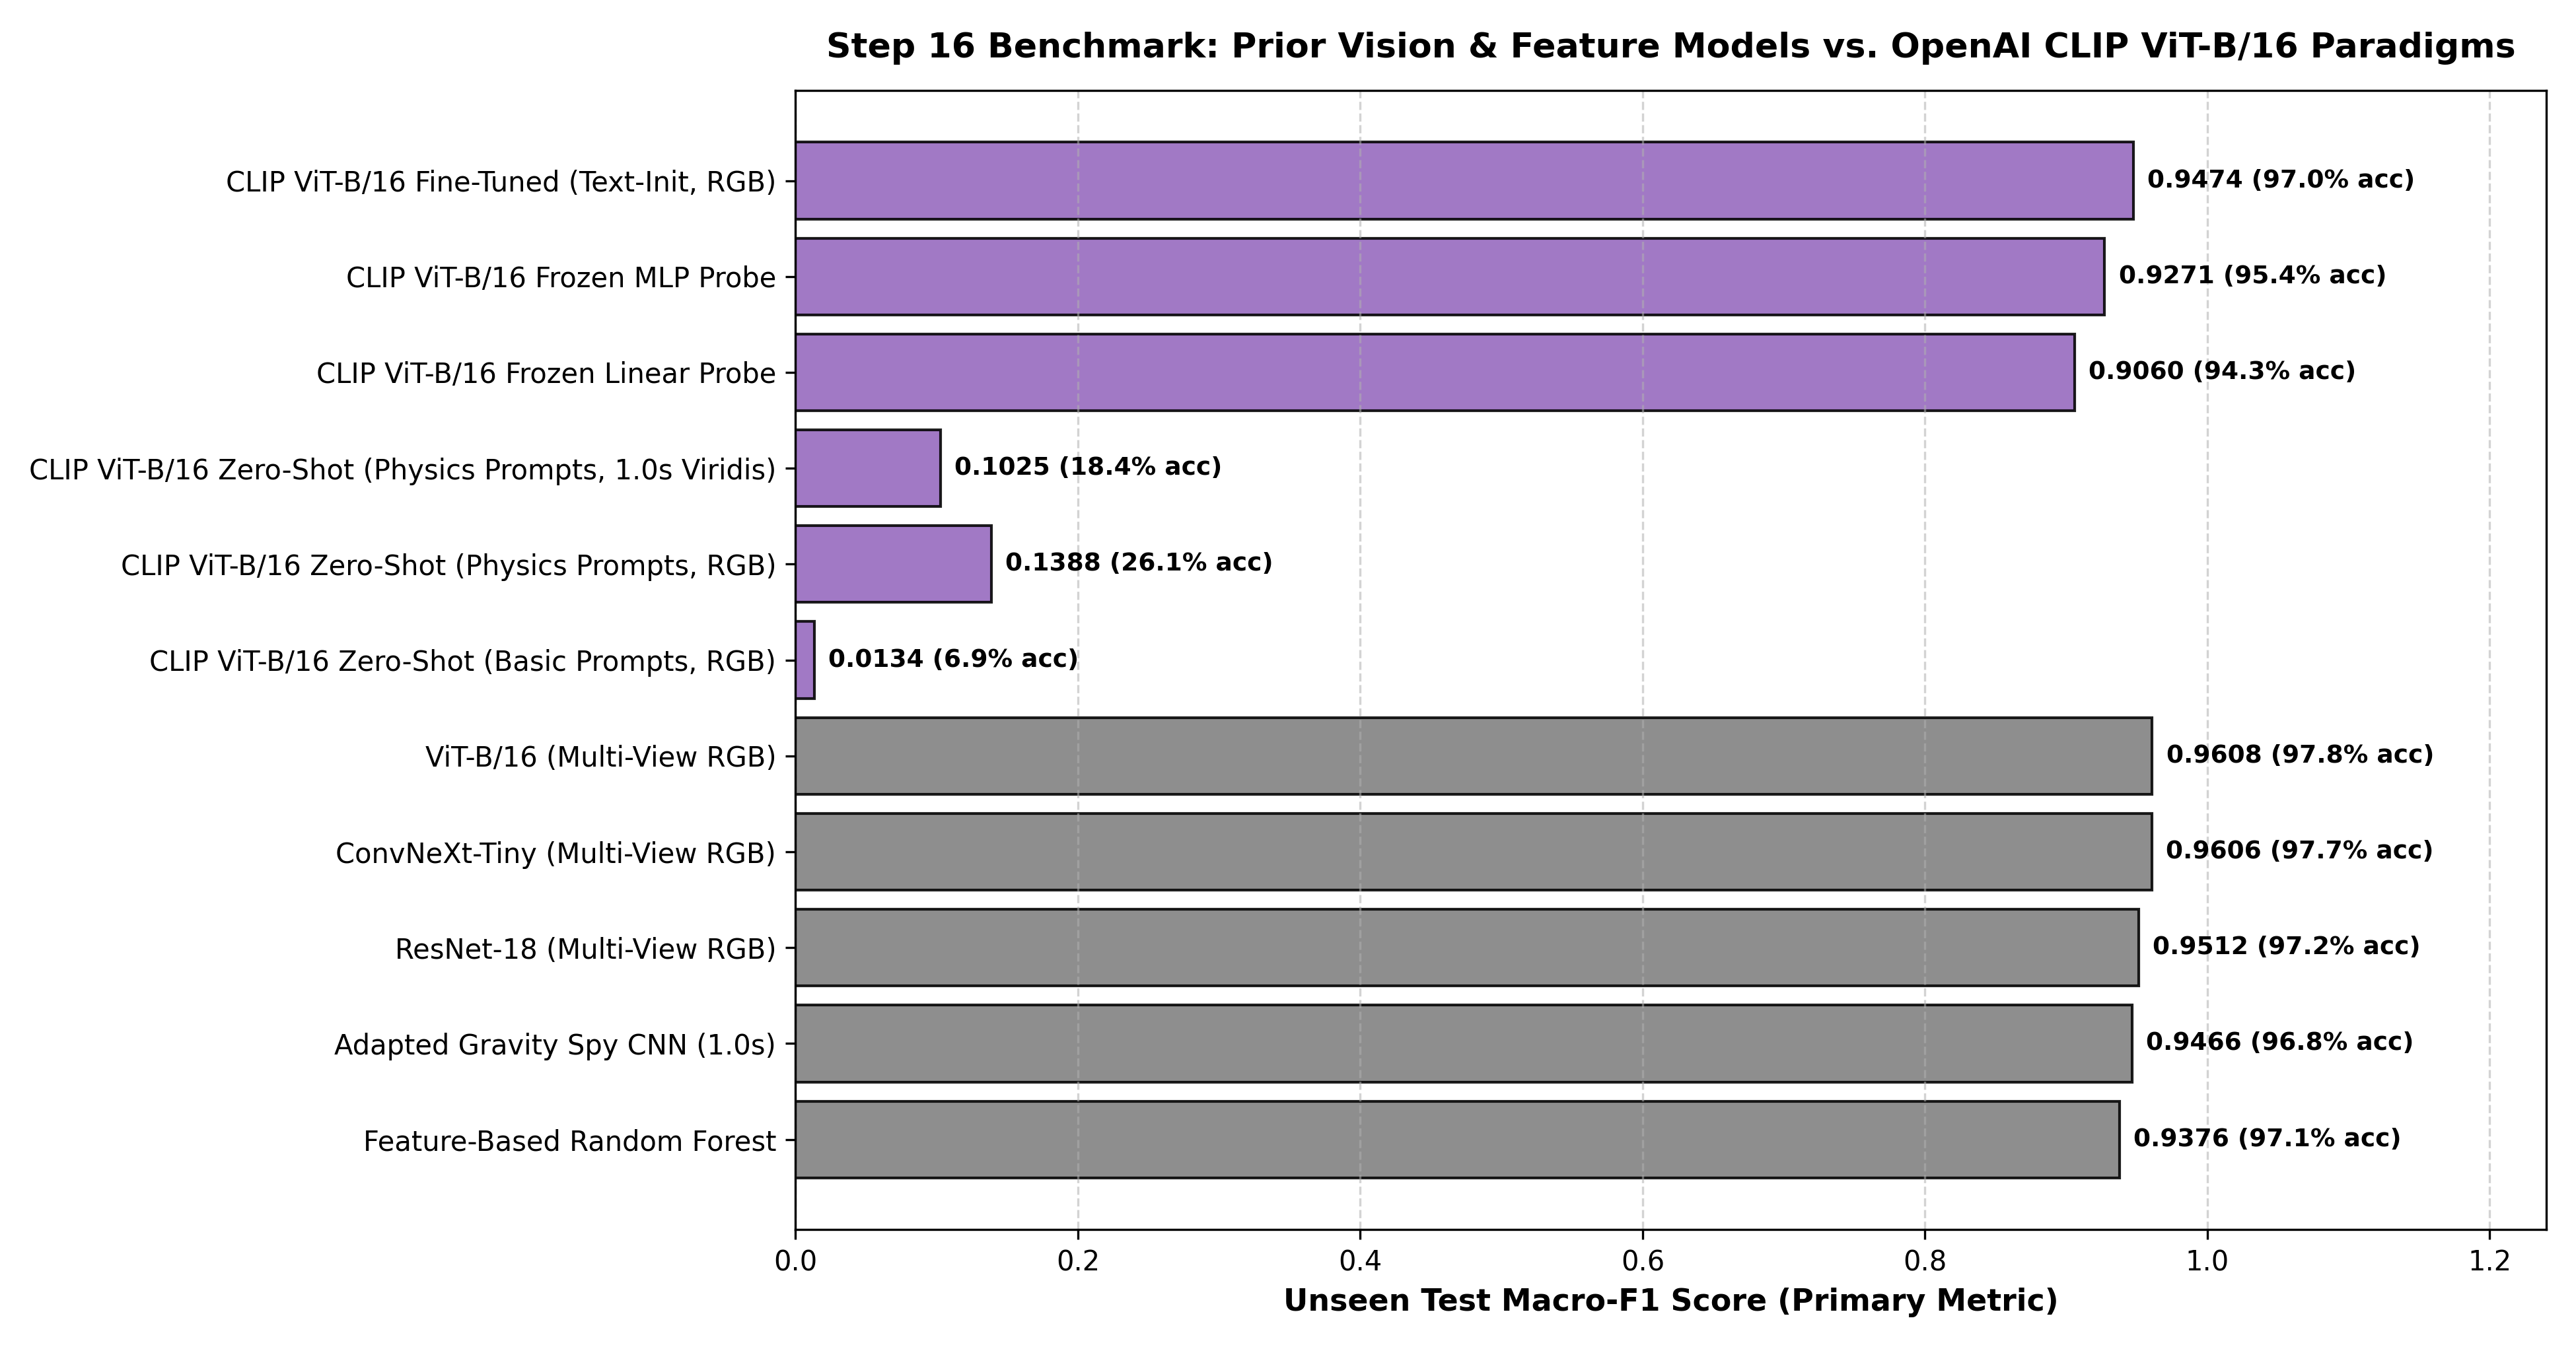


--- Zero-Shot Per-Class Recall & Best Fine-Tuned CLIP Confusion Matrix ---


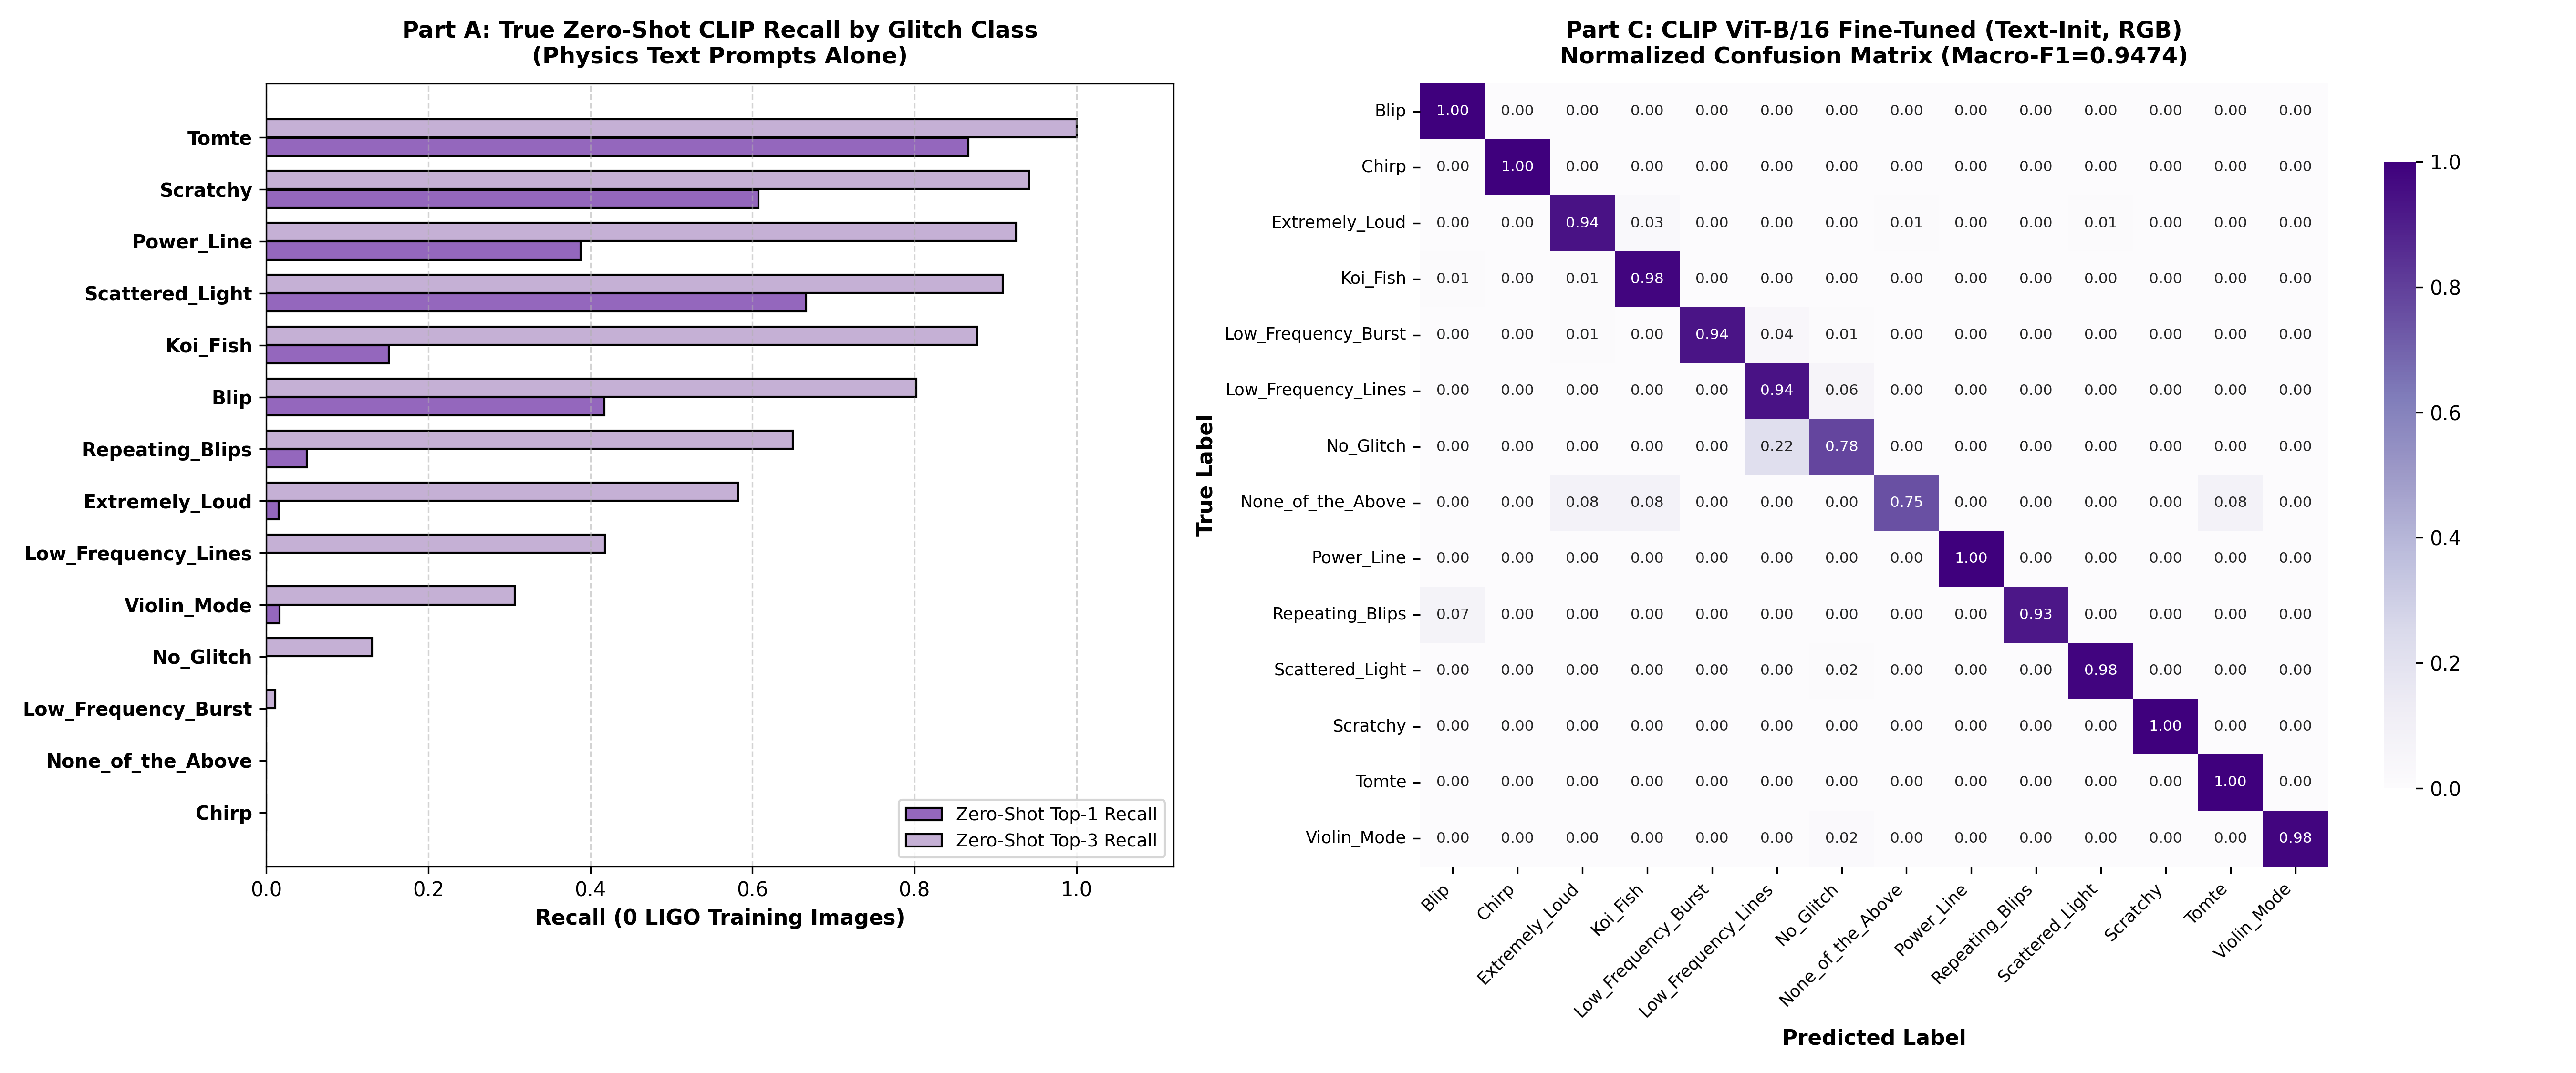

In [4]:
# Step 16.4: Inspect Pooled VLM Results (Parts A, B & C1) & Visuals
import pandas as pd
from IPython.display import display, Image

pooled_df = pd.read_csv("outputs/tables/vlm_clip_pooled_results.csv")
zs_df = pd.read_csv("outputs/tables/vlm_clip_zeroshot_details.csv")
per_cls_df = pd.read_csv("outputs/tables/vlm_clip_per_class_f1.csv")

print("=" * 92)
print(" STEP 16 POOLED LEADERBOARD: OPENAI CLIP ViT-B/16 PARADIGMS (UNSEEN TEST SET, N=951)")
print("=" * 92)
display(pooled_df)

print("\n=== PART A: TRUE ZERO-SHOT TOP-1 vs TOP-3 RECALL PER CLASS (0 LIGO LABELS) ===")
display(zs_df)

print("\n=== PER-CLASS F1 PROGRESSION ACROSS CLIP PARADIGMS ===")
display(per_cls_df)

print("\n--- Unified Benchmark: Prior Models vs. CLIP ViT-B/16 ---")
display(Image(filename="outputs/figures/vlm_clip_benchmark.png"))

print("\n--- Zero-Shot Per-Class Recall & Best Fine-Tuned CLIP Confusion Matrix ---")
display(Image(filename="outputs/figures/vlm_clip_zeroshot_and_cm.png"))

### Explanation of Cell 4: Pooled VLM Analysis — Verified Colab Findings (Parts A, B & C1)
- **Part A (True Zero-Shot — `0` LIGO Training Images):**
  - **Basic class-name prompts failed (`6.94%` Top-1, `24.29%` Top-3, `0.0134` Macro-F1)** because web-pretrained CLIP does not map LIGO jargon (`Tomte`, `Koi_Fish`, `Blip`) to spectrograms without visual descriptions.
  - **Domain-engineered Gravity Spy physics prompts delivered a `10.4×` Macro-F1 jump (`0.0134 → 0.1388`) and `64.46%` Top-3 accuracy (`26.08%` Top-1)** with zero training data! Distinctive morphological classes showed striking zero-shot Top-3 recall: `Tomte` (`100.0%` Top-3 / `86.7%` Top-1), `Scratchy` (`94.1%` Top-3), `Power_Line` (`92.5%`), `Scattered_Light` (`90.9%`, reaching `0.6415` F1 on `1.0s` Viridis), `Koi_Fish` (`87.7%`), and `Blip` (`80.2%`, `0.5124` F1). Subtle physics/noise classes (`Chirp`, `Low_Frequency_Burst`, `None_of_the_Above`) remained near `0%` without domain adaptation.
- **Part B (Completely Frozen CLIP Embeddings — `0` Backbone Fine-Tuning):**
  - **`Frozen Linear Probe` (`7.2K` params):** `94.32%` Acc (`99.58%` Top-3) | **`0.9060` Macro-F1** (beating our Feature Decision Tree `0.8536` by `+0.0524`).
  - **`Frozen MLP Probe` (`136K` params, `9.4s` training):** `95.37%` Acc (`99.79%` Top-3) | **`0.9271` Macro-F1** (`1.0000` F1 on `Chirp` & `Violin_Mode`)—within `0.010` of our 34-feature Random Forest without touching a single CLIP visual weight!
- **Part C1 (Prompt-Init Fine-Tuned `CLIP ViT-B/16` vs. Step 15 ImageNet `ViT-B/16`):**
  - **`CLIP ViT-B/16 Fine-Tuned (Text-Init, RGB)`** reached **`96.95%` Acc (`99.79%` Top-3) | `0.9474` Macro-F1** (`1.0000` F1 on `Chirp`, `Power_Line`, `Scratchy`), beating both Step 9 RF (`0.9376`) and Step 12 4-Layer CNN (`0.9466`).
  - **Key Scientific Takeaway:** In a controlled apples-to-apples `ViT-B/16` showdown, **ImageNet supervised pretraining (`0.9608`) outperformed CLIP contrastive pretraining (`0.9474`) by `+0.0134` Macro-F1**, primarily on faint/fine-textured classes (`No_Glitch` `0.8235` vs `0.7500`, `Repeating_Blips` `1.0000` vs `0.9610`) because web image–text pretraining favors coarse semantic invariance over fine low-SNR pixel texture.

 PART C2: 5-SEED CROSS-DETECTOR TRANSFER & FEW-SHOT ADAPTATION (FROZEN CLIP EMBEDDINGS)


,Direction,Stage,Avg_Target_Train_Samples,Accuracy_Mean (%),Accuracy_Std (%),Macro_F1_Mean,Macro_F1_Std,Gain_vs_SourceProbe,Num_Seeds
0,H1->L1,0% (Text Zero-Shot),0,20.95,1.82,0.1346,0.0184,-0.5460,5
1,H1->L1,0% (Source Probe),0,79.21,2.55,0.6806,0.0289,0.0000,5
2,H1->L1,5% Adapted Probe,88,86.58,3.06,0.7589,0.0391,0.0783,5
3,H1->L1,10% Adapted Probe,176,90.24,1.94,0.8082,0.0352,0.1276,5
4,H1->L1,20% Adapted Probe,351,91.67,2.23,0.8148,0.0496,0.1343,5
5,H1->L1,100% Native Target,1755,92.52,1.86,0.8988,0.0236,0.2182,5
6,L1->H1,0% (Text Zero-Shot),0,27.16,2.03,0.1368,0.0199,-0.5695,5
7,L1->H1,0% (Source Probe),0,84.42,1.27,0.7063,0.0229,0.0000,5
8,L1->H1,5% Adapted Probe,134,88.94,1.54,0.7736,0.0292,0.0673,5
9,L1->H1,10% Adapted Probe,268,90.68,0.91,0.7921,0.0214,0.0859,5



=== PER-CLASS CROSS-DETECTOR RECOVERY ON FROZEN CLIP EMBEDDINGS ===


,Direction,Class,0% (Text Zero-Shot),0% (Source Probe),5% Adapted Probe,10% Adapted Probe,20% Adapted Probe,100% Native Target
0,H1->L1,Blip,0.5262,0.8971,0.9131,0.9433,0.9417,0.9854
1,H1->L1,Chirp,0.0000,0.3809,0.3976,0.5944,0.5309,0.9778
2,H1->L1,Extremely_Loud,0.0737,0.8385,0.8574,0.8983,0.9099,0.9559
3,H1->L1,Koi_Fish,0.0863,0.9307,0.9232,0.9413,0.9457,0.9643
4,H1->L1,Low_Frequency_Burst,0.0000,0.8629,0.8979,0.9164,0.9290,0.9286
5,H1->L1,Low_Frequency_Lines,0.0000,0.7935,0.8380,0.8731,0.9058,0.8684
6,H1->L1,No_Glitch,0.0308,0.4915,0.6446,0.7173,0.6926,0.6503
7,H1->L1,None_of_the_Above,0.0000,0.1000,0.2970,0.3016,0.2381,0.7700
8,H1->L1,Power_Line,0.2752,0.5882,0.7976,0.8608,0.9056,0.8682
9,H1->L1,Repeating_Blips,0.0440,0.6455,0.6091,0.6667,0.7055,0.8373



--- Cross-Detector Comparison: Frozen CLIP Probe vs. Step 13 & Step 15 ---


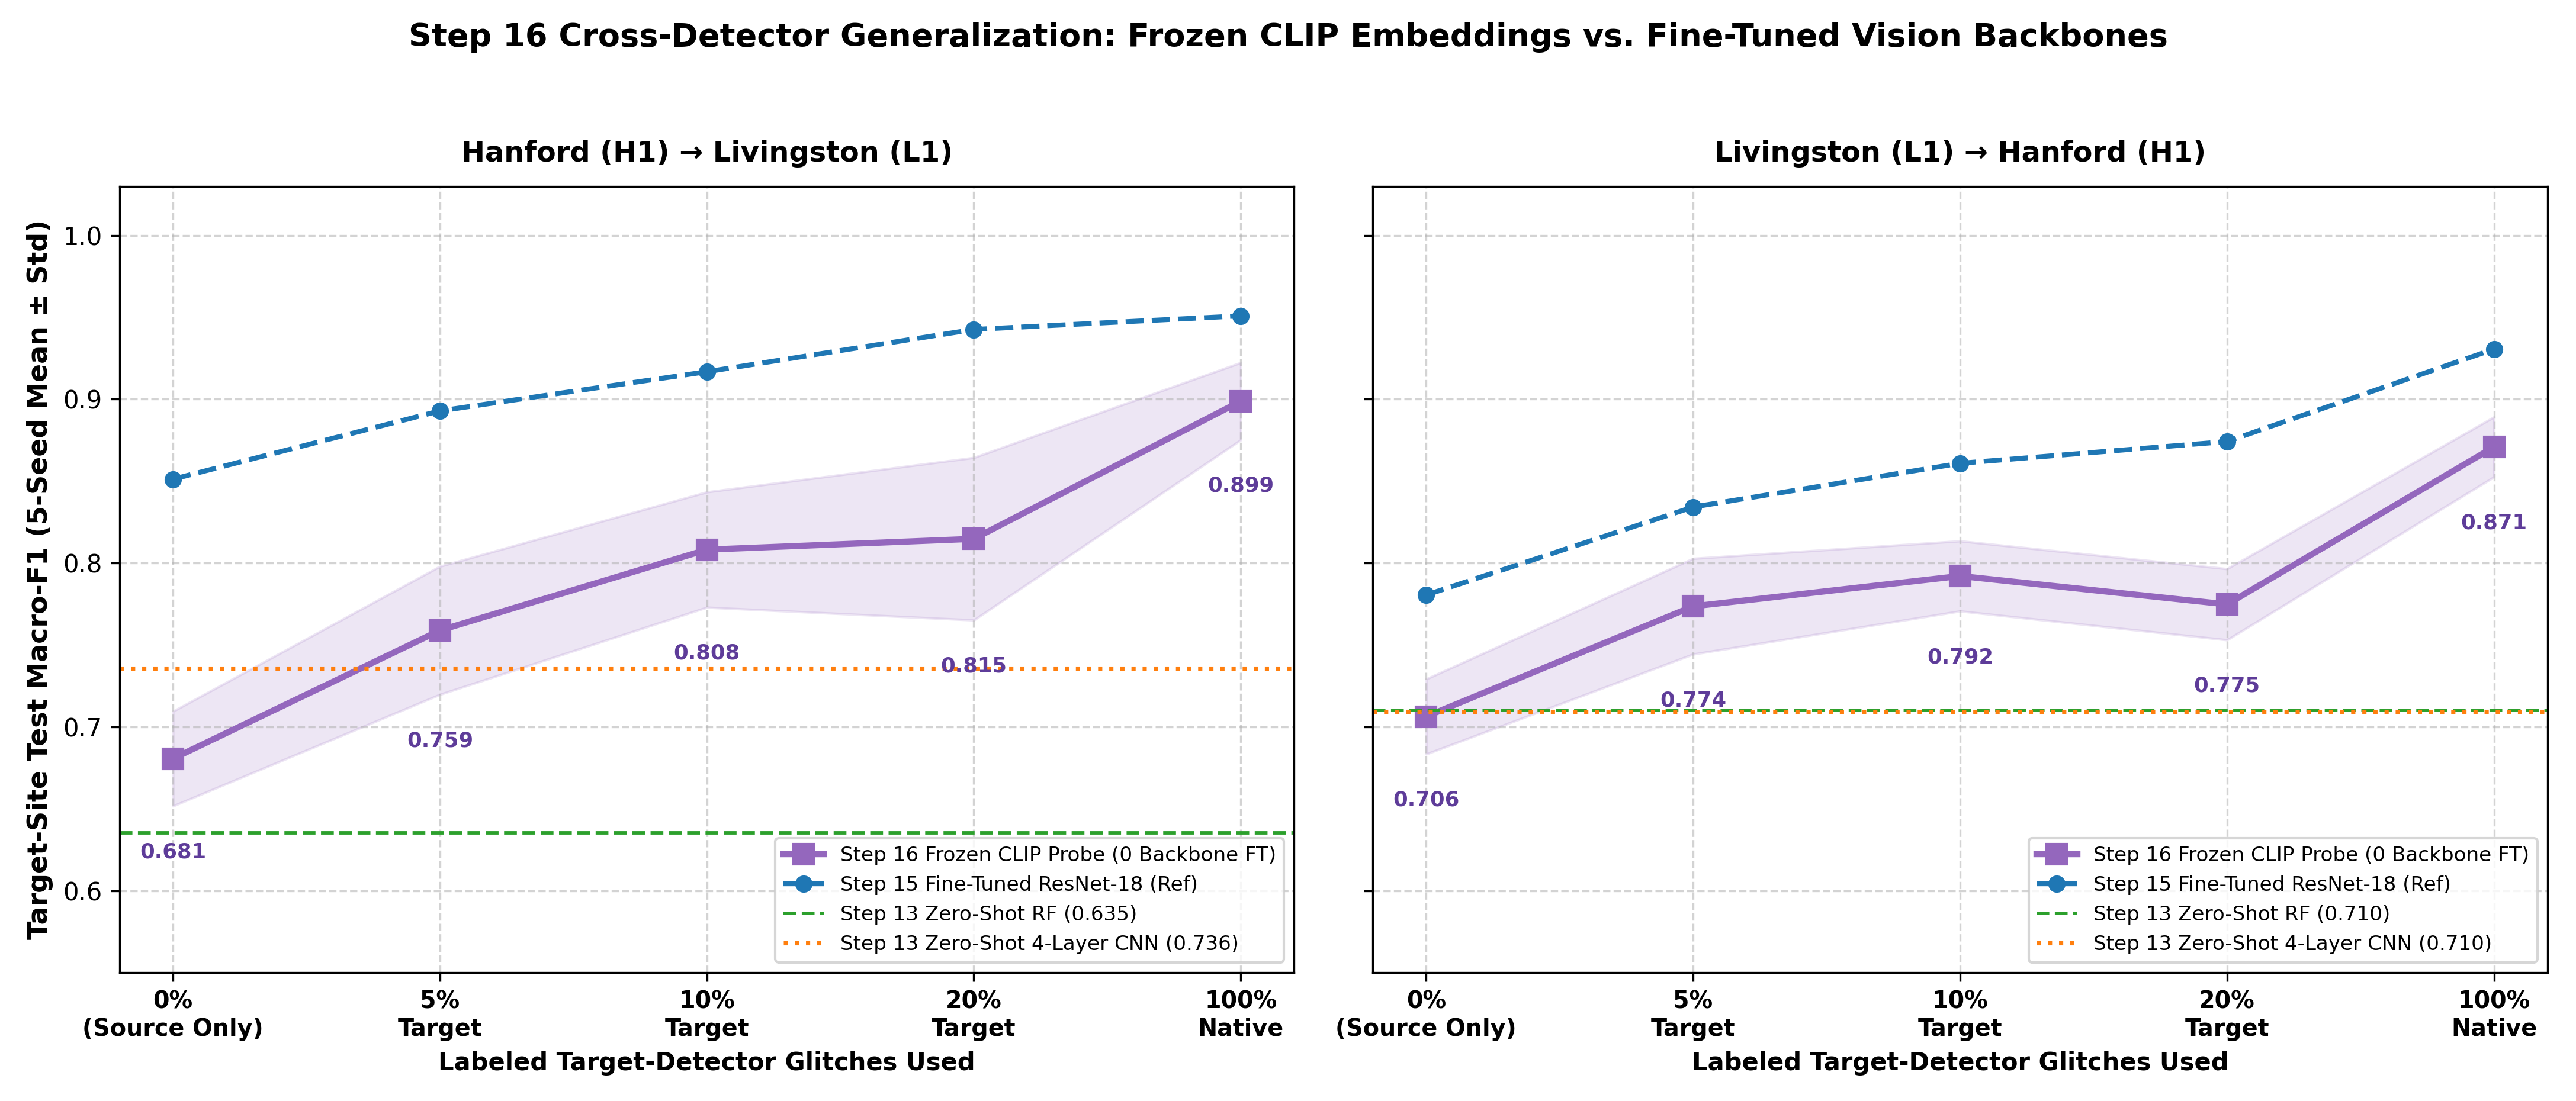

In [5]:
# Step 16.5: Inspect Part C2 Cross-Detector Few-Shot Results (5 Seeds, H1 <-> L1)
import pandas as pd
from IPython.display import display, Image

cd_summary_df = pd.read_csv("outputs/tables/vlm_clip_cross_detector_summary.csv")
cd_per_cls_df = pd.read_csv("outputs/tables/vlm_clip_cross_detector_per_class.csv")

print("=" * 92)
print(" PART C2: 5-SEED CROSS-DETECTOR TRANSFER & FEW-SHOT ADAPTATION (FROZEN CLIP EMBEDDINGS)")
print("=" * 92)
display(cd_summary_df)

print("\n=== PER-CLASS CROSS-DETECTOR RECOVERY ON FROZEN CLIP EMBEDDINGS ===")
display(cd_per_cls_df)

print("\n--- Cross-Detector Comparison: Frozen CLIP Probe vs. Step 13 & Step 15 ---")
display(Image(filename="outputs/figures/vlm_clip_cross_detector_curve.png"))

### Explanation of Cell 5: Cross-Detector Generalization of Frozen CLIP Representations (5-Seed Verified)
- **Zero-Shot Transfer Without Backbone Fine-Tuning (`0%` Target Labels):**
  - **`H1 → L1`:** A linear probe trained strictly on Hanford frozen CLIP embeddings reaches **`0.6806 ± 0.0289`** Macro-F1 on unseen Livingston glitches—beating Step 13 Zero-Shot Feature RF (`0.6355`) by **`+0.0451`** and preserving `Violin_Mode` (`0.8150` F1 vs RF's `0.0637`).
  - **`L1 → H1`:** Starts at **`0.7063 ± 0.0229`**—essentially tying both Step 13 RF (`0.7101`) and Step 13 4-Layer CNN (`0.7095`) with zero GPU training!
- **Rapid CPU-Speed Few-Shot Adaptation (`5%`, `10%`, `20%` Target Labels):**
  - **`H1 → L1`:** Climbs from `0.6806` (`0%`) → **`0.7589`** (`5%`, surpassing Step 13 4-Layer CNN `0.7357`!) → **`0.8082`** (`10%`) → **`0.8148`** (`20%`, with `Violin_Mode` at `0.9928` and `Scattered_Light` jumping `0.5394 → 0.9460`) toward `0.8988` Native L1.
  - **`L1 → H1`:** Climbs from `0.7063` (`0%`) → **`0.7736`** (`5%`) → **`0.7921`** (`10%`, `Chirp` jumping `0.7645 → 0.9492` and `Repeating_Blips` `0.5956 → 0.8711`) toward `0.8709` Native H1.
- **Frozen VLM vs. Fine-Tuned Backbone (Step 15):** While frozen CLIP probes offer an impressive seconds-fast CPU baseline, Step 15's fine-tuned `ResNet-18` (`0.8512 → 0.9426`) stays `+0.13` ahead—demonstrating that visual backbone adaptation remains vital for near-native cross-observatory deployment.

In [6]:
# Step 16.6: Verify Archive Contents & Download `step16_results.zip` (~15 MB)
import os
import zipfile

ZIP_PATH = "/content/ligo-glitch-classification/step16_results.zip"
assert os.path.exists(ZIP_PATH), f"Missing {ZIP_PATH}!"

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()
    print(f"Archive verified: {len(names)} files ({os.path.getsize(ZIP_PATH)/(1024**2):.2f} MB):")
    for n in names:
        print(f"  - {n}")

try:
    from google.colab import files
    files.download(ZIP_PATH)
    print("\nBrowser download triggered for step16_results.zip!")
except ImportError:
    print(f"Not in Colab UI; archive saved at {ZIP_PATH}")

Archive verified: 13 files (12.57 MB):
  - outputs/tables/vlm_clip_pooled_results.csv
  - outputs/tables/vlm_clip_per_class_f1.csv
  - outputs/tables/vlm_clip_zeroshot_details.csv
  - outputs/tables/vlm_clip_finetune_history.csv
  - outputs/tables/vlm_clip_best_test_predictions.csv
  - outputs/tables/vlm_clip_cross_detector_per_seed.csv
  - outputs/tables/vlm_clip_cross_detector_summary.csv
  - outputs/tables/vlm_clip_cross_detector_per_class.csv
  - outputs/figures/vlm_clip_benchmark.png
  - outputs/figures/vlm_clip_zeroshot_and_cm.png
  - outputs/figures/vlm_clip_cross_detector_curve.png
  - outputs/models/clip_embeddings_frozen.npz
  - outputs/models/clip_embeddings_finetuned.npz


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Browser download triggered for step16_results.zip!


### Explanation of Cell 6: Bringing Step 16 Results & Embeddings Home (Integrated)
- **All 13 Artifacts Extracted & Integrated Locally:**
  - **8 Step 16 CSV Tables** + updated master `benchmark_comparison.csv` (15 rows), `per_class_f1_summary.csv` (14 × 15), and `step16_four_way_agreement.csv`.
  - **3 Publication-Grade 300-DPI PNG Charts** in `outputs/figures/` (`vlm_clip_benchmark.png`, `vlm_clip_zeroshot_and_cm.png`, `vlm_clip_cross_detector_curve.png`).
  - **Compact Embedding Archives (`5.73 MB` & `5.71 MB`):** `outputs/models/clip_embeddings_frozen.npz` and `outputs/models/clip_embeddings_finetuned.npz` (zero-pickle verified, all `6,340 × 512` `float16` vectors ready for Step 17 Multimodal Hybrid Fusion!).
- **4-Way Complementarity Discovery:** `CLIP ViT-B/16` rescues `6` errors made by ImageNet `ViT-B/16`—including `XNK7vTF2CT` (`Blip`), the single non-unanimous glitch previously missed by RF, 4-Layer CNN, and ImageNet ViT—pushing the **`RF + ImageNet ViT + CLIP ViT` Oracle Fusion Ceiling to `99.37%` (`945 / 951`)**, leaving only **`6` unanimously label-ambiguous glitches (`0.63%`)**!